# 29 — Spatial + Wind Refinement of GeoMAE-Inspired Anomaly Candidates

## Goal

This notebook follows the supervisor's feedback: a hotspot may look anomalous temporally, but if it appears close to an earlier hotspot source — especially in a direction consistent with the wind — it may still be spatially explainable.

```text
GeoMAE robust anomaly candidate
            ↓
previous hotspot source search (t-1 to t-3)
            ↓
distance + wind-direction consistency
            ↓
spatially/wind explainable? → deprioritize
            ↓
refined anomaly candidate
```

Important terminology:
- `robust anomaly candidate` = frozen output from NB25;
- `spatially explainable` = nearby / wind-aligned prior hotspot context exists;
- `refined anomaly candidate` = robust anomaly with weak spatial-wind explanation;
- these are **not ground-truth false positives** because no true anomaly label is available.

Primary working settings:
- lookback = **3 days**;
- immediate-neighbor radius = **40 km** (roughly a 3×3 neighborhood at 0.25°);
- broader wind-context radius = **75 km**;
- wind alignment threshold = **cosine ≥ 0.5** (about ±60° toward the target).

A sensitivity table is produced so these thresholds are not treated as uniquely correct.

In [2]:
from pathlib import Path
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 300)
pd.set_option("display.width", 220)

In [3]:
# Resolve project paths
cwd = Path.cwd()
candidate_roots = [cwd, cwd.parent, Path('/content/skripsi-karhut'), Path('/content/drive/MyDrive/skripsi-karhut')]
PROJECT_ROOT = None
for root in candidate_roots:
    data_path = root/'data'/'processed'/'regional_025'/'karhut_ml_dataset_regional_025.csv'
    nb25_dir = root/'model_results'/'final_masked_temporal_anomaly'/'t2'/'exports'
    candidate_path = nb25_dir/'august_final_robust_anomaly_candidates.csv'
    if data_path.exists() and candidate_path.exists():
        PROJECT_ROOT = root
        break
if PROJECT_ROOT is None:
    raise FileNotFoundError('Could not locate the regional dataset and NB25 exports. Set PROJECT_ROOT manually if needed.')

DATA_PATH = PROJECT_ROOT/'data'/'processed'/'regional_025'/'karhut_ml_dataset_regional_025.csv'
NB25_EXPORT_DIR = PROJECT_ROOT/'model_results'/'final_masked_temporal_anomaly'/'t2'/'exports'
RESULT_DIR = PROJECT_ROOT/'model_results'/'spatial_wind_anomaly_refinement'/'t2'
EXPORT_DIR = RESULT_DIR/'exports'
FIGURE_DIR = RESULT_DIR/'figures'
EXPORT_DIR.mkdir(parents=True, exist_ok=True)
FIGURE_DIR.mkdir(parents=True, exist_ok=True)
print('PROJECT_ROOT:', PROJECT_ROOT)
print('RESULT_DIR  :', RESULT_DIR)

PROJECT_ROOT: c:\Users\Asus\Documents\skripsi-karhut
RESULT_DIR  : c:\Users\Asus\Documents\skripsi-karhut\model_results\spatial_wind_anomaly_refinement\t2


In [4]:
# Working configuration
LOOKBACK_DAYS = 3
NEAR_RADIUS_KM = 40.0
WIND_RADIUS_KM = 75.0
WIND_ALIGNMENT_THRESHOLD = 0.5
MIN_WIND_SPEED = 0.5
TARGET_DATE = pd.Timestamp('2026-08-02')

print('LOOKBACK_DAYS            :', LOOKBACK_DAYS)
print('NEAR_RADIUS_KM           :', NEAR_RADIUS_KM)
print('WIND_RADIUS_KM           :', WIND_RADIUS_KM)
print('WIND_ALIGNMENT_THRESHOLD :', WIND_ALIGNMENT_THRESHOLD)

LOOKBACK_DAYS            : 3
NEAR_RADIUS_KM           : 40.0
WIND_RADIUS_KM           : 75.0
WIND_ALIGNMENT_THRESHOLD : 0.5


In [5]:
# Load data
regional = pd.read_csv(DATA_PATH, parse_dates=['date'])
candidates = pd.read_csv(NB25_EXPORT_DIR/'august_final_robust_anomaly_candidates.csv', parse_dates=['date'])

required_regional = {'date','cell_id','grid_lat','grid_lon','fire_active','fire_count','frp_sum','wind_u_mean','wind_v_mean'}
missing = sorted(required_regional - set(regional.columns))
if missing:
    raise ValueError('Regional dataset missing: ' + ', '.join(missing))
required_candidate = {'date','cell_id','grid_lat','grid_lon','ensemble_median_rank','high_seed_count'}
missing = sorted(required_candidate - set(candidates.columns))
if missing:
    raise ValueError('NB25 candidate export missing: ' + ', '.join(missing))

regional = regional.sort_values(['date','cell_id']).reset_index(drop=True)
candidates = candidates.sort_values(['date','cell_id']).reset_index(drop=True)
print('Regional rows:', len(regional))
print('Cells:', regional['cell_id'].nunique())
print('Frozen robust anomaly candidates:', len(candidates))

Regional rows: 16625
Cells: 133
Frozen robust anomaly candidates: 620


## Spatial and wind interpretation

For a prior hotspot source `A` and candidate target `B`, cosine alignment compares the **source-cell daily wind vector** `(wind_u_mean, wind_v_mean)` with the geographic direction `A → B`.

- `+1` = wind points directly toward the target;
- `0` = approximately perpendicular;
- `-1` = wind points away from the target.

This is **wind-aligned neighboring hotspot exposure**, not proof of physical fire spread or causality.

In [6]:
EARTH_RADIUS_KM = 6371.0088

def haversine_km(lat1, lon1, lat2, lon2):
    lat1 = np.radians(np.asarray(lat1, dtype=float))
    lon1 = np.radians(np.asarray(lon1, dtype=float))
    lat2 = np.radians(np.asarray(lat2, dtype=float))
    lon2 = np.radians(np.asarray(lon2, dtype=float))
    dlat = lat2-lat1
    dlon = lon2-lon1
    a = np.sin(dlat/2)**2 + np.cos(lat1)*np.cos(lat2)*np.sin(dlon/2)**2
    return 2*EARTH_RADIUS_KM*np.arcsin(np.sqrt(np.clip(a,0,1)))

def source_to_target_unit(source_lat, source_lon, target_lat, target_lon):
    mean_lat = np.radians((float(source_lat)+float(target_lat))/2)
    east_km = (float(target_lon)-float(source_lon))*111.320*np.cos(mean_lat)
    north_km = (float(target_lat)-float(source_lat))*110.574
    norm = float(np.hypot(east_km,north_km))
    if norm == 0:
        return np.nan, np.nan
    return east_km/norm, north_km/norm

def wind_alignment(source_u, source_v, east_unit, north_unit):
    if not np.isfinite(east_unit) or not np.isfinite(north_unit):
        return np.nan
    mag = float(np.hypot(source_u, source_v))
    if not np.isfinite(mag) or mag < MIN_WIND_SPEED:
        return np.nan
    return float((float(source_u)*east_unit + float(source_v)*north_unit)/mag)

In [7]:
# Active hotspot source rows indexed by date
active_sources = regional[regional['fire_active'].eq(1)].copy()
sources_by_date = {date:g.copy() for date,g in active_sources.groupby('date')}
print('Active source cell-days:', len(active_sources))

Active source cell-days: 3625


In [8]:
# Build prior-source pairs for each candidate
pair_rows=[]
for cand in candidates.itertuples(index=False):
    cand_date = pd.Timestamp(cand.date)
    for lag in range(1, LOOKBACK_DAYS+1):
        source_date = cand_date - pd.Timedelta(days=lag)
        source_day = sources_by_date.get(source_date, pd.DataFrame())
        if source_day.empty:
            continue
        for src in source_day.itertuples(index=False):
            distance_km = float(haversine_km(src.grid_lat,src.grid_lon,cand.grid_lat,cand.grid_lon))
            east_unit,north_unit = source_to_target_unit(src.grid_lat,src.grid_lon,cand.grid_lat,cand.grid_lon)
            alignment = wind_alignment(src.wind_u_mean,src.wind_v_mean,east_unit,north_unit)
            pair_rows.append({
                'candidate_date':cand_date,
                'candidate_cell_id':cand.cell_id,
                'candidate_lat':cand.grid_lat,
                'candidate_lon':cand.grid_lon,
                'candidate_anomaly_rank':cand.ensemble_median_rank,
                'candidate_high_seed_count':cand.high_seed_count,
                'source_date':source_date,
                'source_lag_days':lag,
                'source_cell_id':src.cell_id,
                'source_lat':src.grid_lat,
                'source_lon':src.grid_lon,
                'source_fire_count':src.fire_count,
                'source_frp_sum':src.frp_sum,
                'source_wind_u':src.wind_u_mean,
                'source_wind_v':src.wind_v_mean,
                'distance_km':distance_km,
                'wind_alignment':alignment,
                'same_cell_source':src.cell_id == cand.cell_id,
            })

pairs = pd.DataFrame(pair_rows)
if pairs.empty:
    raise RuntimeError('No prior hotspot sources found.')
pairs['near_source'] = pairs['distance_km'] <= NEAR_RADIUS_KM
pairs['wind_aligned_source'] = ((pairs['distance_km'] <= WIND_RADIUS_KM) & (pairs['wind_alignment'] >= WIND_ALIGNMENT_THRESHOLD))
print('Candidate-source pairs:', len(pairs))
print('Candidates represented:', pairs[['candidate_date','candidate_cell_id']].drop_duplicates().shape[0])
display(pairs.head())

Candidate-source pairs: 118658
Candidates represented: 620


,candidate_date,candidate_cell_id,candidate_lat,candidate_lon,candidate_anomaly_rank,candidate_high_seed_count,source_date,source_lag_days,source_cell_id,source_lat,source_lon,source_fire_count,source_frp_sum,source_wind_u,source_wind_v,distance_km,wind_alignment,same_cell_source,near_source,wind_aligned_source
0,2026-08-01,regional025_10_27,-1.875,114.875,0.909774,5,2026-07-31,1,regional025_10_25,-1.875,114.375,2.0,7.17,-3.695568,3.574262,55.567772,-0.718806,False,False,False
1,2026-08-01,regional025_10_27,-1.875,114.875,0.909774,5,2026-07-31,1,regional025_10_28,-1.875,115.125,2.0,5.25,-6.032866,2.551639,27.783886,0.921007,False,True,True
2,2026-08-01,regional025_10_27,-1.875,114.875,0.909774,5,2026-07-31,1,regional025_10_31,-1.875,115.875,6.0,30.49,-4.191200,4.821991,111.135543,0.656015,False,False,False
3,2026-08-01,regional025_10_27,-1.875,114.875,0.909774,5,2026-07-31,1,regional025_10_33,-1.875,116.375,1.0,4.99,-3.965265,12.513319,166.703312,0.302080,False,False,False
4,2026-08-01,regional025_10_27,-1.875,114.875,0.909774,5,2026-07-31,1,regional025_11_31,-1.625,115.875,1.0,12.08,-4.271045,5.116786,114.566865,0.436803,False,False,False


## Candidate-level refinement

Each robust candidate is summarized using:
- nearest hotspot in the previous 3 days;
- whether the same cell was active previously;
- presence of a source within 40 km;
- maximum wind alignment within 75 km;
- nearest wind-aligned source.

Working status:
- `strong` explanation: same-cell recurrence, or nearby context plus wind support;
- `moderate` explanation: nearby **or** wind-aligned context;
- `low` explanation: neither is found.

Only `low` becomes the default `refined_anomaly_candidate`.

In [9]:
summary_rows=[]
for (candidate_date,candidate_cell_id),g in pairs.groupby(['candidate_date','candidate_cell_id']):
    g=g.sort_values(['distance_km','source_lag_days'])
    nearest=g.iloc[0]
    near=g[g['distance_km'] <= NEAR_RADIUS_KM].copy()
    wind_ctx=g[(g['distance_km'] <= WIND_RADIUS_KM) & g['wind_alignment'].notna()].copy()
    aligned=wind_ctx[wind_ctx['wind_alignment'] >= WIND_ALIGNMENT_THRESHOLD].copy()
    best_wind = None if wind_ctx.empty else wind_ctx.sort_values(['wind_alignment','distance_km'], ascending=[False,True]).iloc[0]
    nearest_aligned = None if aligned.empty else aligned.sort_values('distance_km').iloc[0]

    same_cell_prev=bool(g['same_cell_source'].any())
    near_any=bool(len(near)>0)
    aligned_any=bool(len(aligned)>0)
    strong=bool(same_cell_prev or (near_any and aligned_any))
    moderate=bool(near_any or aligned_any)
    level='strong' if strong else ('moderate' if moderate else 'low')

    summary_rows.append({
        'date':candidate_date,
        'cell_id':candidate_cell_id,
        'nearest_prev_hotspot_km':float(nearest['distance_km']),
        'nearest_prev_hotspot_lag_days':int(nearest['source_lag_days']),
        'nearest_prev_source_cell_id':nearest['source_cell_id'],
        'nearest_prev_source_lat':float(nearest['source_lat']),
        'nearest_prev_source_lon':float(nearest['source_lon']),
        'same_cell_active_prev3':same_cell_prev,
        'near_source_within_40km':near_any,
        'n_sources_within_40km':int(len(near)),
        'max_wind_alignment_within_75km':(float(best_wind['wind_alignment']) if best_wind is not None else np.nan),
        'wind_aligned_source_within_75km':aligned_any,
        'nearest_wind_aligned_source_km':(float(nearest_aligned['distance_km']) if nearest_aligned is not None else np.nan),
        'wind_aligned_source_cell_id':(nearest_aligned['source_cell_id'] if nearest_aligned is not None else np.nan),
        'spatial_wind_explanation':level,
        'deprioritized_spatial_wind':moderate,
        'refined_anomaly_candidate':level=='low',
    })

context=pd.DataFrame(summary_rows)
refined=candidates.merge(context,on=['date','cell_id'],how='left',validate='one_to_one')
refined['no_prior_source_found']=refined['nearest_prev_hotspot_km'].isna()
refined.loc[refined['no_prior_source_found'],'spatial_wind_explanation']='low'
refined.loc[refined['no_prior_source_found'],'deprioritized_spatial_wind']=False
refined.loc[refined['no_prior_source_found'],'refined_anomaly_candidate']=True

display(refined[['date','cell_id','ensemble_median_rank','high_seed_count','nearest_prev_hotspot_km','nearest_prev_hotspot_lag_days','same_cell_active_prev3','near_source_within_40km','max_wind_alignment_within_75km','wind_aligned_source_within_75km','spatial_wind_explanation','refined_anomaly_candidate']].head(40))

,date,cell_id,ensemble_median_rank,high_seed_count,nearest_prev_hotspot_km,nearest_prev_hotspot_lag_days,same_cell_active_prev3,near_source_within_40km,max_wind_alignment_within_75km,wind_aligned_source_within_75km,spatial_wind_explanation,refined_anomaly_candidate
0,2026-08-01,regional025_10_27,0.909774,5,27.783886,1,False,True,0.994205,True,strong,False
1,2026-08-01,regional025_11_33,0.902256,5,27.798770,1,False,True,0.953283,True,strong,False
2,2026-08-01,regional025_12_24,0.872180,5,27.790766,1,False,True,0.944113,True,strong,False
3,2026-08-01,regional025_12_26,0.969925,5,27.790766,1,False,True,0.783307,True,strong,False
4,2026-08-01,regional025_13_24,0.834586,5,27.793412,1,False,True,0.997056,True,strong,False
5,2026-08-01,regional025_2_27,0.849624,5,27.735218,2,False,True,0.709726,True,strong,False
6,2026-08-01,regional025_3_26,1.000000,5,27.798770,2,False,True,0.642820,True,strong,False
7,2026-08-01,regional025_3_27,0.842105,5,27.798770,1,False,True,0.949277,True,strong,False
8,2026-08-01,regional025_3_28,0.939850,5,27.798770,2,False,True,0.999999,True,strong,False
9,2026-08-01,regional025_3_31,0.924812,5,0.000000,1,True,True,-0.321480,False,strong,False


In [10]:
# Main counts
counts = refined['spatial_wind_explanation'].value_counts().reindex(['strong','moderate','low'], fill_value=0)
n_robust=len(refined)
n_deprioritized=int(refined['deprioritized_spatial_wind'].sum())
n_refined=int(refined['refined_anomaly_candidate'].sum())

print('=== SPATIAL + WIND REFINEMENT REVIEW ===')
print('Original GeoMAE robust anomaly candidates :', n_robust)
print('Strong spatial-wind explanation           :', int(counts['strong']))
print('Moderate spatial-wind explanation         :', int(counts['moderate']))
print('Low spatial-wind explanation              :', int(counts['low']))
print('Deprioritized by spatial/wind context      :', n_deprioritized)
print('Refined anomaly candidates                 :', n_refined)
print('Refined share                              :', round(n_refined/n_robust,4) if n_robust else np.nan)

summary_table=pd.DataFrame({'stage':['Original robust anomaly','Spatial/wind explainable → deprioritized','Refined anomaly candidate'],'count':[n_robust,n_deprioritized,n_refined]})
display(summary_table)

=== SPATIAL + WIND REFINEMENT REVIEW ===
Original GeoMAE robust anomaly candidates : 620
Strong spatial-wind explanation           : 607
Moderate spatial-wind explanation         : 12
Low spatial-wind explanation              : 1
Deprioritized by spatial/wind context      : 619
Refined anomaly candidates                 : 1
Refined share                              : 0.0016


,stage,count
0,Original robust anomaly,620
1,Spatial/wind explainable → deprioritized,619
2,Refined anomaly candidate,1


## Threshold sensitivity

To avoid overclaiming one threshold, this section varies:
- nearby-source radius: 30 / 40 / 50 km;
- wind radius: 75 / 100 km;
- alignment threshold: 0.3 / 0.5 / 0.7.

In [11]:
sensitivity_rows=[]
for near_radius in [30.0,40.0,50.0]:
    for wind_radius in [75.0,100.0]:
        for align_threshold in [0.3,0.5,0.7]:
            deprioritized_flags=[]
            represented=0
            for key,g in pairs.groupby(['candidate_date','candidate_cell_id']):
                represented += 1
                same_cell=bool(g['same_cell_source'].any())
                near_any=bool((g['distance_km'] <= near_radius).any())
                aligned_any=bool(((g['distance_km'] <= wind_radius) & (g['wind_alignment'] >= align_threshold)).any())
                deprioritized_flags.append(same_cell or near_any or aligned_any)
            n_dep=int(np.sum(deprioritized_flags))
            n_ref=len(candidates)-n_dep
            sensitivity_rows.append({
                'near_radius_km':near_radius,
                'wind_radius_km':wind_radius,
                'alignment_threshold':align_threshold,
                'deprioritized_count':n_dep,
                'refined_count':n_ref,
                'refined_fraction':n_ref/len(candidates),
                'candidate_groups_with_pairs':represented,
            })
sensitivity=pd.DataFrame(sensitivity_rows)
display(sensitivity)

,near_radius_km,wind_radius_km,alignment_threshold,deprioritized_count,refined_count,refined_fraction,candidate_groups_with_pairs
0,30.0,75.0,0.3,618,2,0.003226,620
1,30.0,75.0,0.5,618,2,0.003226,620
2,30.0,75.0,0.7,617,3,0.004839,620
3,30.0,100.0,0.3,619,1,0.001613,620
4,30.0,100.0,0.5,619,1,0.001613,620
5,30.0,100.0,0.7,618,2,0.003226,620
6,40.0,75.0,0.3,619,1,0.001613,620
7,40.0,75.0,0.5,619,1,0.001613,620
8,40.0,75.0,0.7,618,2,0.003226,620
9,40.0,100.0,0.3,619,1,0.001613,620


## Before vs after map

The right panel does **not silently delete** candidates:
- original robust anomalies remain represented;
- candidates with spatial/wind explanation are marked separately;
- refined candidates are highlighted;
- dashed source-to-candidate lines show the prior hotspot used as spatial context.

In [12]:
day_all=regional[regional['date'].eq(TARGET_DATE)].copy()
day_hot=day_all[day_all['fire_active'].eq(1)].copy()
day_refined=refined[refined['date'].eq(TARGET_DATE)].copy()
if day_refined.empty:
    raise ValueError(f'No robust anomaly candidates on {TARGET_DATE.date()}. Change TARGET_DATE.')
day_keep=day_refined[day_refined['refined_anomaly_candidate']].copy()
day_drop=day_refined[day_refined['deprioritized_spatial_wind']].copy()
print('TARGET_DATE:', TARGET_DATE.date())
print('Hotspot-positive cells:', len(day_hot))
print('Original robust candidates:', len(day_refined))
print('Deprioritized:', len(day_drop))
print('Refined:', len(day_keep))

TARGET_DATE: 2026-08-02
Hotspot-positive cells: 35
Original robust candidates: 21
Deprioritized: 21
Refined: 0


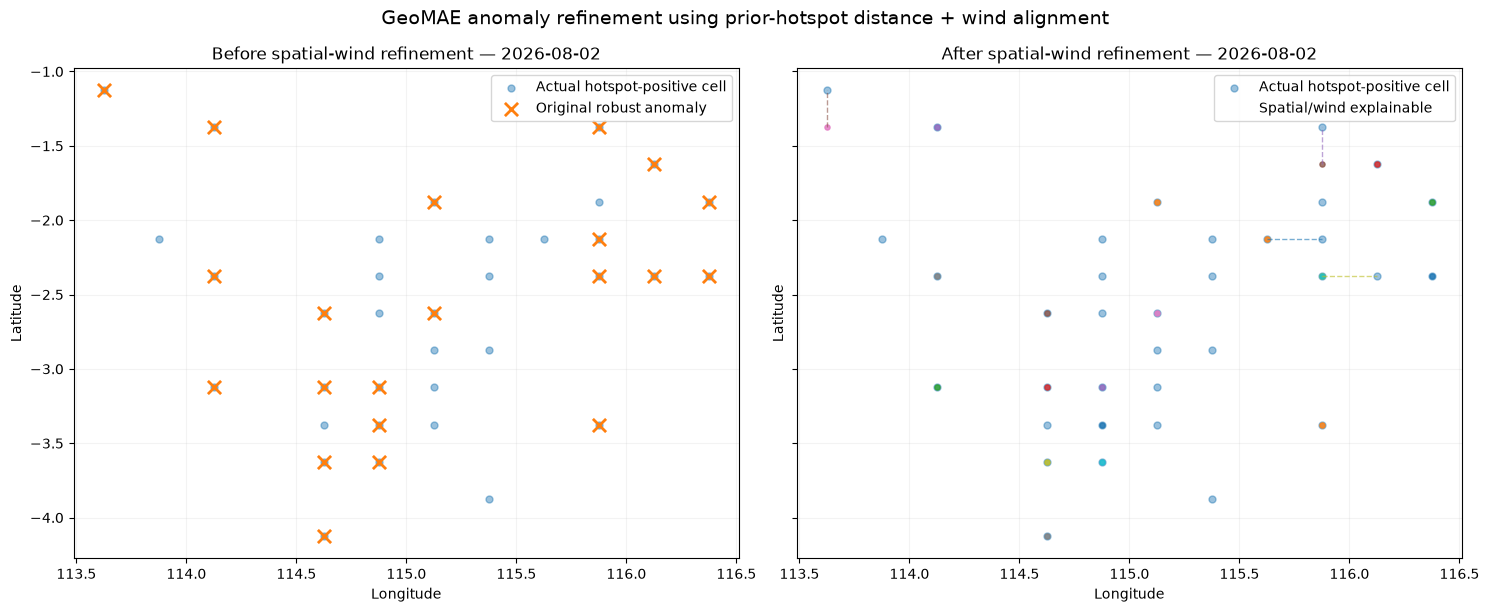

Saved: c:\Users\Asus\Documents\skripsi-karhut\model_results\spatial_wind_anomaly_refinement\t2\figures\before_after_spatial_wind_2026-08-02.png


In [13]:
fig,axes=plt.subplots(1,2,figsize=(15,6.2),sharex=True,sharey=True)
ax_before,ax_after=axes
for ax in axes:
    ax.scatter(day_hot['grid_lon'],day_hot['grid_lat'],s=25,alpha=0.45,label='Actual hotspot-positive cell')

ax_before.scatter(day_refined['grid_lon'],day_refined['grid_lat'],marker='x',s=90,linewidths=2.0,label='Original robust anomaly')
ax_before.set_title(f'Before spatial-wind refinement — {TARGET_DATE.date()}')

if len(day_drop):
    ax_after.scatter(day_drop['grid_lon'],day_drop['grid_lat'],marker='o',s=70,facecolors='none',linewidths=1.6,label='Spatial/wind explainable')
    for row in day_drop.itertuples(index=False):
        if pd.notna(row.nearest_prev_source_lon) and pd.notna(row.nearest_prev_source_lat):
            ax_after.plot([row.nearest_prev_source_lon,row.grid_lon],[row.nearest_prev_source_lat,row.grid_lat],linestyle='--',linewidth=1.0,alpha=0.6)
            ax_after.scatter([row.nearest_prev_source_lon],[row.nearest_prev_source_lat],marker='.',s=55,alpha=0.8)
if len(day_keep):
    ax_after.scatter(day_keep['grid_lon'],day_keep['grid_lat'],marker='x',s=110,linewidths=2.2,label='Refined anomaly candidate')
ax_after.set_title(f'After spatial-wind refinement — {TARGET_DATE.date()}')

for ax in axes:
    ax.set_xlabel('Longitude')
    ax.set_ylabel('Latitude')
    ax.grid(alpha=0.15)
    ax.legend(loc='best')
fig.suptitle('GeoMAE anomaly refinement using prior-hotspot distance + wind alignment',fontsize=14)
plt.tight_layout()
fig_path=FIGURE_DIR/f'before_after_spatial_wind_{TARGET_DATE.date()}.png'
plt.savefig(fig_path,dpi=200,bbox_inches='tight')
plt.show()
print('Saved:', fig_path)

In [14]:
# Evidence table for selected date
presentation_cols=['date','cell_id','grid_lat','grid_lon','ensemble_median_rank','high_seed_count','nearest_prev_hotspot_km','nearest_prev_hotspot_lag_days','same_cell_active_prev3','near_source_within_40km','max_wind_alignment_within_75km','wind_aligned_source_within_75km','spatial_wind_explanation','refined_anomaly_candidate']
display(day_refined[presentation_cols].sort_values(['refined_anomaly_candidate','ensemble_median_rank'],ascending=[False,False]))

,date,cell_id,grid_lat,grid_lon,ensemble_median_rank,high_seed_count,nearest_prev_hotspot_km,nearest_prev_hotspot_lag_days,same_cell_active_prev3,near_source_within_40km,max_wind_alignment_within_75km,wind_aligned_source_within_75km,spatial_wind_explanation,refined_anomaly_candidate
44,2026-08-02,regional025_8_32,-2.375,116.125,1.000000,5,27.774891,2,False,True,0.997855,True,strong,False
46,2026-08-02,regional025_9_31,-2.125,115.875,0.984962,5,27.779653,1,False,True,0.944417,True,strong,False
45,2026-08-02,regional025_8_33,-2.375,116.375,0.977444,5,0.000000,2,True,True,0.920900,True,strong,False
30,2026-08-02,regional025_12_31,-1.375,115.875,0.969925,5,27.798770,2,False,True,0.943759,True,strong,False
39,2026-08-02,regional025_5_27,-3.125,114.875,0.962406,5,0.000000,1,True,True,0.999734,True,strong,False
32,2026-08-02,regional025_1_26,-4.125,114.625,0.954887,5,0.000000,1,True,True,0.207568,False,strong,False
36,2026-08-02,regional025_4_31,-3.375,115.875,0.947368,5,0.000000,1,True,True,0.806098,True,strong,False
26,2026-08-02,regional025_10_28,-1.875,115.125,0.939850,5,0.000000,2,True,True,0.999799,True,strong,False
42,2026-08-02,regional025_8_24,-2.375,114.125,0.932331,5,0.000000,1,True,True,0.838210,True,strong,False
31,2026-08-02,regional025_13_22,-1.125,113.625,0.924812,5,27.798770,2,False,True,0.999946,True,strong,False


In [15]:
# Export outputs
REFINED_PATH=EXPORT_DIR/'august_robust_anomaly_spatial_wind_refined.csv'
PAIR_PATH=EXPORT_DIR/'candidate_prior_hotspot_source_pairs.csv'
SENSITIVITY_PATH=EXPORT_DIR/'spatial_wind_refinement_sensitivity.csv'
SUMMARY_PATH=EXPORT_DIR/'spatial_wind_refinement_summary.csv'
refined.to_csv(REFINED_PATH,index=False)
pairs.to_csv(PAIR_PATH,index=False)
sensitivity.to_csv(SENSITIVITY_PATH,index=False)
summary_table.to_csv(SUMMARY_PATH,index=False)
print('Saved outputs:')
print('-',REFINED_PATH)
print('-',PAIR_PATH)
print('-',SENSITIVITY_PATH)
print('-',SUMMARY_PATH)

Saved outputs:
- c:\Users\Asus\Documents\skripsi-karhut\model_results\spatial_wind_anomaly_refinement\t2\exports\august_robust_anomaly_spatial_wind_refined.csv
- c:\Users\Asus\Documents\skripsi-karhut\model_results\spatial_wind_anomaly_refinement\t2\exports\candidate_prior_hotspot_source_pairs.csv
- c:\Users\Asus\Documents\skripsi-karhut\model_results\spatial_wind_anomaly_refinement\t2\exports\spatial_wind_refinement_sensitivity.csv
- c:\Users\Asus\Documents\skripsi-karhut\model_results\spatial_wind_anomaly_refinement\t2\exports\spatial_wind_refinement_summary.csv


# What to show the supervisor tomorrow

Show these three things:

1. **Main counts**
   - original robust anomaly candidates;
   - spatial/wind-explainable → deprioritized;
   - refined anomaly candidates.

2. **Before vs after map**
   - explainable candidates are not silently deleted;
   - refined candidates remain highlighted;
   - source-to-candidate lines explain the spatial reasoning.

3. **Evidence table**
   - anomaly rank;
   - nearest previous hotspot distance;
   - lag day;
   - wind alignment;
   - final refinement status.

Suggested explanation:

> “GeoMAE tetap menghasilkan anomaly berdasarkan temporal reconstruction. Setelah itu saya menambahkan spatial-wind refinement. Saya mencari hotspot pada tiga hari sebelumnya, menghitung jaraknya terhadap kandidat, lalu mengecek apakah arah angin dari source mengarah ke candidate. Kandidat yang masih punya penjelasan spatial atau wind saya deprioritaskan. Kandidat yang tetap terisolasi menjadi refined anomaly candidate. Ini belum saya sebut false positive karena saya belum punya ground-truth anomaly.”